# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [50]:
# importar librerías
import pandas as pd

In [51]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [52]:
# mostrar las primeras 5 filas
df.head ()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [53]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


El dataset tiene 40,000 filas y 9 columnas. No se observan valores ausentes en ninguna columna. Las columnas converted (int64) y gasto (float64) tienen el tipo de dato correcto para el análisis. La columna date es de tipo object y debería ser datetime, por lo que se convertirá. Se continúa con el análisis.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [54]:
# Verificar usuarios únicos
print("Total de filas:", len(df))
print("Usuarios únicos:", df["user_id"].nunique())
print("Duplicados en user_id:", df["user_id"].duplicated().sum())

Total de filas: 40000
Usuarios únicos: 40000
Duplicados en user_id: 0


 **Variable `date`**  
Explorar rango de fechas

In [55]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [56]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [57]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [58]:
# Resumen estadístico de usuarios que se convirtieron
df[df["converted"] == 1]["gasto"].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [59]:

# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
for col in ["landing", "region", "dispositivo", "traffic_source", "user_type"]:
    print(f"\n{col}:")
    print(df[col].value_counts())


Conteo de categorías:

landing:
B    20018
A    19982
Name: landing, dtype: int64

region:
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

dispositivo:
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

traffic_source:
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

user_type:
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


In [60]:
df["date"] = pd.to_datetime(df["date"])

Todas las columnas categóricas tienen valores esperados. La columna landing contiene únicamente las versiones A (19,982 usuarios) y B (20,018 usuarios), con una distribución prácticamente balanceada. No se observan categorías mal escritas ni valores inesperados en region (5 categorías), dispositivo (Mobile y Desktop), traffic_source (Organic, Ads, Email y Referral) ni user_type (Nuevo y Recurrente). Se continúa con el análisis.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [61]:
# Gasto por versión
gasto_A = df[(df["converted"] == 1) & (df["landing"] == "A")]["gasto"]
gasto_B = df[(df["converted"] == 1) & (df["landing"] == "B")]["gasto"]

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** ...
- **Hipótesis alternativa (H₁):** ...

In [62]:

# Aplicar prueba
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=False)

# Visualizar resultados
print(f"Estadístico : {t_stat}")
print(f"Valor p: {p_value}")

Estadístico : -9.48101092267275
Valor p: 3.627602231521493e-21


In [63]:
alpha = 0.05
print("Gasto promedio A:", gasto_A.mean())
print("Gasto promedio B:", gasto_B.mean())

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay diferencia significativa en el gasto promedio.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de diferencia en el gasto promedio.")

Gasto promedio A: 61.0865724522293
Gasto promedio B: 68.74536005009392
Rechazamos la hipótesis nula: hay diferencia significativa en el gasto promedio.


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula. Con un nivel de significancia de 0.05, el valor p (≈ 3.6 × 10⁻²¹) es mucho menor que alfa, por lo que hay evidencia estadística de que el gasto promedio de los clientes es distinto entre la página A y la página B.

**Interpretación de negocio:**  
Los clientes que llegan a la página B gastan en promedio 68.75, en cambio a 61.09 en la página A, una diferencia de 7.66 por cliente (aproximadamente 12.5% más). Como la prueba descarta que esta diferencia se deba al azar, la página B genera mayor valor económico por cliente. Esto sugiere que B es más efectiva para impulsar un mayor gasto una vez que el usuario se convierte. Sin embargo, esta conclusión se limita a los usuarios que se convirtieron en clientes: todavía falta comparar la tasa de conversión entre ambas páginas para saber si B también atrae a más clientes, y con eso decidir cuál versión implementar.


---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** ...
- **Hipótesis alternativa (H₁):** ...

In [64]:

# Número de usuarios convertidos por página
conversiones = df.groupby("landing")["converted"].sum()

# Total de usuarios por página
totales = df.groupby("landing")["converted"].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)

Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [65]:
alpha = 0.05
print(f"Tasa A: {conteos[0] / num_observaciones[0]:.4f}")
print(f"Tasa B: {conteos[1] / num_observaciones[1]:.4f}")

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay diferencia significativa en la tasa de conversión.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de diferencia en la tasa de conversión.")

Tasa A: 0.1257
Tasa B: 0.1596
Rechazamos la hipótesis nula: hay diferencia significativa en la tasa de conversión.


In [66]:
# Aplicar prueba
from statsmodels.stats.proportion import proportions_ztest

conteos = [conversiones["A"], conversiones["B"]]
num_observaciones = [totales["A"], totales["B"]]

z_stat, p_value = proportions_ztest(conteos, num_observaciones)

# Visualizar resultados
print(f"Estadístico : {z_stat}")
print(f"Valor p: {p_value}")

Estadístico : -9.677362674655983
Valor p: 3.7629765627523803e-22


### 📝 Conclusión e interpretación

**Decisión:**  
(¿Se rechaza o no la hipótesis nula?)
Si, se rechaza la hipótesis nula. Con un nivel de significancia de 0.05, el valor p (≈ [pega tu valor]) es menor que alfa, por lo que hay evidencia estadística de que la tasa de conversión es distinta entre la página A y la página B.

**Interpretación de negocio:**  
La página B convierte al 15.96% de los usuarios, frente al 12.57% de la página A, una diferencia de 3.4 puntos porcentuales (cerca de 27% más conversiones en términos relativos). En cantidades absolutas, B generó 3,194 clientes contra 2,512 de A, con grupos de tamaño casi idéntico, por lo que la diferencia no se explica por tener más usuarios. Como la prueba descarta que esta diferencia se deba al azar, la página B es más efectiva para convertir visitantes en clientes. Sumado al paso 2, donde B también logró un mayor gasto por cliente, la página B supera a la A tanto en cantidad de clientes como en valor por cliente.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** ...
- **Hipótesis alternativa (H₁):** ...

In [67]:
# Tabla de contingencia: cantidades absolutas
tabla = pd.crosstab(df["traffic_source"], df["converted"])
print(tabla)

# Tasa de conversión por fuente de tráfico (%)
tasas = pd.crosstab(df["traffic_source"], df["converted"], normalize="index") * 100
print()
print(tasas.round(2))

converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549

converted           0      1
traffic_source              
Ads             85.26  14.74
Email           85.01  14.99
Organic         86.21  13.79
Referral        86.12  13.88


In [68]:

# Aplicar prueba
from scipy.stats import chi2_contingency

chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

print(f"Estadístico chi-cuadrado: {chi2_stat}")
print(f"Valor p: {p_value}")
print(f"Grados de libertad: {dof}")

Estadístico chi-cuadrado: 8.662108841397938
Valor p: 0.0341375947833914
Grados de libertad: 3


In [69]:
alpha = 0.05
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre la fuente de tráfico y la conversión.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")

Rechazamos la hipótesis nula: hay evidencia de asociación entre la fuente de tráfico y la conversión.


### 📝 Conclusión e interpretación

**Decisión:**  
(¿Se rechaza o no la hipótesis nula?)
Se rechaza la hipótesis nula. Con un nivel de significancia de 0.05, el valor p (≈ 0.034) es menor que alfa, por lo que hay evidencia estadística de asociación entre la fuente de tráfico y la conversión.

**Interpretación de negocio:**  
Explica qué indican los resultados considerando tanto las cantidades absolutas como las tasas de conversión.
En cantidades absolutas, Organic es el canal que más clientes aporta (2,480), seguido de Ads (1,759), Email (918) y Referral (549), pero esto se debe en gran parte a que Organic es también el canal con más usuarios. Al comparar las tasas de conversión, el orden cambia: Email (14.99%) y Ads (14.74%) convierten mejor, mientras que Referral (13.88%) y Organic (13.79%) convierten menos. Aunque la prueba indica que la conversión no es independiente de la fuente de tráfico, la diferencia entre el mejor y el peor canal es de apenas 1.2 puntos porcentuales y el valor p está cerca del umbral, por lo que el efecto es modesto. Email y Ads parecen canales ligeramente más eficientes por usuario, pero la fuente de tráfico no es un factor decisivo en la conversión.


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** ...
- **Hipótesis alternativa (H₁):** ...

In [70]:
# Tabla de contingencia: cantidades absolutas
tabla = pd.crosstab(df["user_type"], df["converted"])
print(tabla)

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [71]:
# Tasa de conversión por tipo de usuario (%)
tasas = pd.crosstab(df["user_type"], df["converted"], normalize="index") * 100
print(tasas.round(2))

converted       0      1
user_type               
Nuevo       85.64  14.36
Recurrente  85.91  14.09


In [72]:
# Aplicar prueba
# Aplicar prueba
from scipy.stats import chi2_contingency

chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

print(f"Estadístico chi-cuadrado: {chi2_stat}")
print(f"Valor p: {p_value}")
print(f"Grados de libertad: {dof}")

alpha = 0.05
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de asociación entre el tipo de usuario y la conversión.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.")



Estadístico chi-cuadrado: 0.5134849494478645
Valor p: 0.4736341272301974
Grados de libertad: 1
No rechazamos la hipótesis nula: no hay evidencia suficiente de asociación entre las variables.


### 📝 Conclusión e interpretación

**Decisión:**  
(¿Se rechaza o no la hipótesis nula?)
No se rechaza la hipótesis nula. Con un nivel de significancia de 0.05, el valor p (≈ 0.474) es mayor que alfa, por lo que no hay evidencia estadística suficiente de asociación entre el tipo de usuario y la conversión.

**Interpretación de negocio:**  
Explica qué indica el resultado.
En cantidades absolutas, los usuarios nuevos generan más clientes (3,738) que los recurrentes (1,968), pero esto se debe a que son más numerosos (26,033 contra 13,967). Al comparar las tasas de conversión, ambos perfiles se comportan de forma casi idéntica: 14.36% en usuarios nuevos y 14.09% en recurrentes, una diferencia de apenas 0.27 puntos porcentuales que puede explicarse por el azar. Por lo tanto, el tipo de usuario no parece influir en la probabilidad de convertirse en esta ocasión. Esto indica que la página no necesita estrategias distintas para cada perfil y que ser un usuario recurrente no implica por sí solo una mayor probabilidad de conversión en esta visita.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

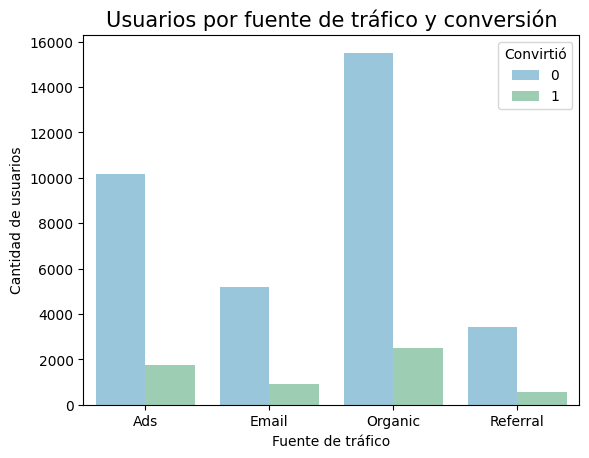

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

# Cantidad de usuarios que convirtieron y no convirtieron por fuente de tráfico
orden = sorted(df["traffic_source"].unique())

sns.countplot(data=df, x="traffic_source", hue="converted", order=orden, palette=["#8ecae6", "#95d5b2"])
plt.title("Usuarios por fuente de tráfico y conversión", fontsize=15)
plt.xlabel("Fuente de tráfico")
plt.ylabel("Cantidad de usuarios")
plt.legend(title="Convirtió")
plt.show()

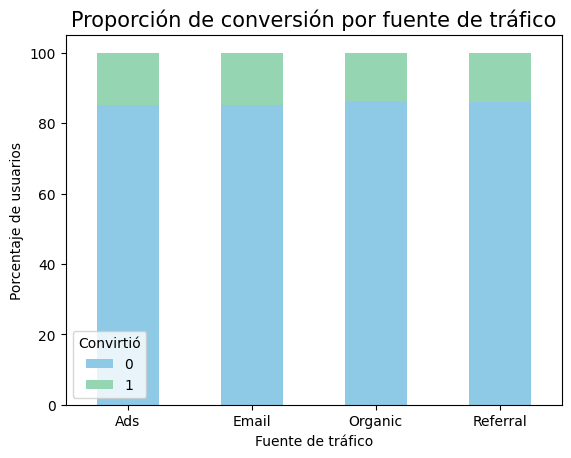

In [74]:
# Proporción de usuarios que convirtieron y no convirtieron por fuente de tráfico
prop = pd.crosstab(df["traffic_source"], df["converted"], normalize="index") * 100

prop.plot(kind="bar", stacked=True, color=["#8ecae6", "#95d5b2"])
plt.title("Proporción de conversión por fuente de tráfico", fontsize=15)
plt.xlabel("Fuente de tráfico")
plt.ylabel("Porcentaje de usuarios")
plt.legend(title="Convirtió")
plt.xticks(rotation=0)
plt.show()


En el gráfico de cantidades absolutas, Organic es el canal que más usuarios aporta y también el que más clientes genera (2,480), seguido de Ads (1,759), Email (918) y Referral (549). Sin embargo, esto refleja principalmente el tamaño de cada canal. En el gráfico de proporciones, las tasas de conversión son muy parecidas: Email (14.99%) y Ads (14.74%) están ligeramente por encima de Referral (13.88%) y Organic (13.79%). La diferencia entre el mejor y el peor canal es de apenas 1.2 puntos porcentuales, lo que refuerza el resultado de la prueba chi-cuadrada: la asociación entre la fuente de tráfico y la conversión es estadísticamente significativa, pero débil en términos prácticos.

### Relación entre el tipo de usuario y la conversión

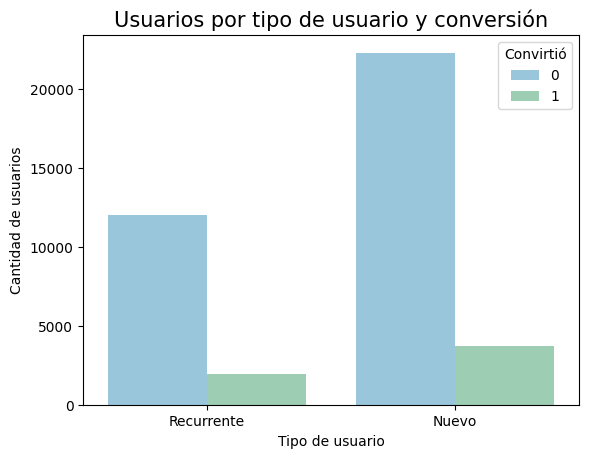

In [75]:
# Cantidad de usuarios que convirtieron y no convirtieron por tipo de usuario
sns.countplot(data=df, x="user_type", hue="converted", palette=["#8ecae6", "#95d5b2"])
plt.title("Usuarios por tipo de usuario y conversión", fontsize=15)
plt.xlabel("Tipo de usuario")
plt.ylabel("Cantidad de usuarios")
plt.legend(title="Convirtió")
plt.show()

In [76]:
# Cantidades exactas que respaldan el gráfico
print(pd.crosstab(df["user_type"], df["converted"]))

converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


En cantidades absolutas, los usuarios nuevos son mayoría y generan más clientes (3,738) que los recurrentes (1,968). Esto refleja el tamaño de cada grupo (26,033 nuevos contra 13,967 recurrentes), no que un perfil convierta mejor que otro. En ambos tipos de usuario, la cantidad de quienes no convirtieron es mucho mayor que la de quienes sí lo hicieron.

In [77]:
# Proporción de conversión por tipo de usuario (%)
prop = pd.crosstab(df["user_type"], df["converted"], normalize="index") * 100
print(prop.round(2))

converted       0      1
user_type               
Nuevo       85.64  14.36
Recurrente  85.91  14.09


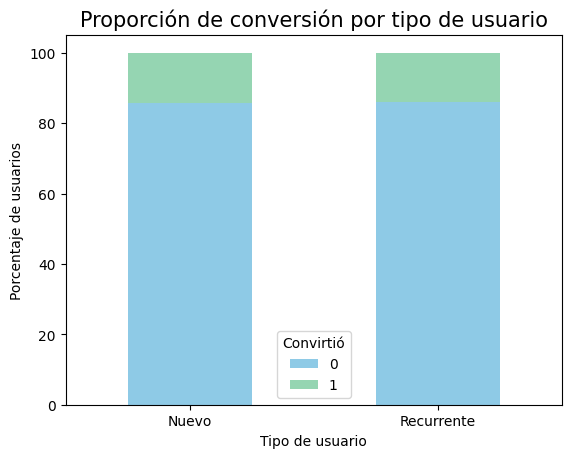

In [78]:
prop.plot(kind="bar", stacked=True, color=["#8ecae6", "#95d5b2"])
plt.title("Proporción de conversión por tipo de usuario", fontsize=15)
plt.xlabel("Tipo de usuario")
plt.ylabel("Porcentaje de usuarios")
plt.legend(title="Convirtió")
plt.xticks(rotation=0)
plt.show()

Al comparar proporciones, ambos perfiles se comportan casi igual: 14.36% de los usuarios nuevos y 14.09% de los recurrentes se convirtieron en clientes, una diferencia de apenas 0.27 puntos porcentuales. Las dos barras apiladas se ven prácticamente idénticas, lo que coincide con la prueba chi-cuadrada (valor p ≈ 0.474): no hay evidencia de que el tipo de usuario influya en la conversión.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- La página B registra un gasto promedio de 68.75 por cliente, frente a 61.09 de la página A (7.66 más, ≈ 12.5%).
- La prueba t de Welch confirma que la diferencia es estadísticamente significativa (p < 0.001).
- **Interpretación:** los clientes que llegan por la página B generan mayor valor económico que los de la página A.


<br>

**Tasa de conversión:**
- La página B convierte al 15.96% de sus usuarios (3,194 de 20,018), contra 12.57% de la página A (2,512 de 19,982), una diferencia de 3.4 puntos porcentuales.
- La prueba z de proporciones confirma que la diferencia es estadísticamente significativa (p < 0.001).
- **Interpretación:** la página B atrae a más clientes, cerca de 27% más conversiones en términos relativos. Junto con el gasto, B supera a A en cantidad y en valor por cliente.

---

## 📊 Segmentación por fuente de tráfico

- Organic aporta más clientes en volumen (2,480), pero tiene la tasa más baja (13.79%). Email (14.99%) y Ads (14.74%) son los canales con mejor tasa de conversión.
- **Interpretación:** existe una asociación significativa entre la fuente de tráfico y la conversión (p = 0.034), pero es débil: la diferencia entre el mejor y el peor canal es de solo 1.2 puntos porcentuales.
 ---

## 📊 Segmentación por tipo de usuario
- Los usuarios nuevos convierten al 14.36% y los recurrentes al 14.09%, una diferencia de apenas 0.27 puntos porcentuales.
- **Interpretación:** no hay evidencia significativa de que el tipo de usuario influya en la conversión (p = 0.474). Ambos perfiles responden de forma similar.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

## 💡 Recomendaciones de negocio:

- Implementar la página B: supera a la A tanto en tasa de conversión como en gasto promedio por cliente.
- Mantener y reforzar Email y Ads, que muestran las mejores tasas. Como la diferencia entre canales es pequeña, conviene validarlo con un experimento antes de mover presupuesto.
- Mejorar la conversión de Organic, el canal con más volumen pero la tasa más baja, ya que cualquier mejora ahí tendría el mayor impacto en número de clientes.
- No diseñar estrategias distintas por tipo de usuario, porque nuevos y recurrentes se comportan igual.